## Phase 01: Signal EDA & Acoustic Feature Engineering

### Objective
In Phase 0, I started the process of EDA through checking the Metadata associated with the audio dataset alone. In this Phase, I will establish clean, leakage-free acoustic representations from the 1,440-utterance RAVDESS corpus. 

This is the phase where I take a look at the audio files themselves. After performing some basic spot checks, I will use the [LibRosa MFCC](https://librosa.org/doc/main/api/generated/librosa.feature.mfcc.html) library. This is a popular open-source library used to analzye digital audio and perform feature extraction. I plan to

- validates lexical and duration balance
- go beyond the spoken statements and isolate individual vocal signs that indicate emotion (e.g. sighs, whimpers)
- check for artifacts like noise and 
- a mapping of the raw 16kHz signlas into a structured, *low dimensional* feature space that I can use for the next phase of modeling

### Primary Deliverable
`data/processed/ser_features.parquet` — A structured tabular dataset comprising 1,440 clips across verified metadata labels and engineered acoustic descriptors, ready for speaker-independent cross-validation.

### Key Goals
1. **Lexical & Duration Invariance:** Statement identity ("Kids..." vs. "Dogs...") exhibits uniform duration distributions across emotional classes, proving **statement phrasing is not a predictive confounder**. 

    This will help identify if clip duration can be justified as a viable predictive feature or if it introduces bias.

2. **Audio Cleanup:** Raw audio clips could contain leading/trailing studio silence. I will check for this by analyzing the waveforms and trying an energy-based silence trimming (`top_db=25`). 
 
    The goal is to isolate the **active signal** while preserving expressive acoustic transients (sobs, sighs, and emphatic aspirated stops)
   
3. **Feature Extraction**: After performing cleanup of the clips and outliers, the ultiamte goal of this phase is to determine w**hich specific acoustic features** carry discriminatory signal to structure the pipeline stages (e.g., separating gender routing features from emotion classification features).

   * **Spectral Envelope & Timbre:** 13 MFCCs plus first-order deltas ($\Delta$) capture static vocal-tract geometry and dynamic spectral transitions over time.
   * **Fundamental Frequency ($F_0$):** Extracted via probabilistic YIN (`pyin`) across voiced segments to establish pitch baseline and variance—critical for Stage 1 gender routing and Stage 2 arousal discrimination.
   * **Energy & Spectral Dynamics:** Root Mean Square (RMS) energy, Spectral Centroid, Bandwidth, Rolloff, Flatness, and Zero-Crossing Rate quantify vocal effort, brightness, and harmonicity.

4. Finally, I would like to perform a **multicollinearity audit** and see if I could prune redundant acoustic statistics to prevent variance inflation in linear and tree-based estimators before moving to formal feature selection or Ridge/Lasso regularization. This can be done through pairwise correlation checks (|r| ≥ 0.85), as well as exploring open-source signal processing techniques like the **Discrete Cosine Transform (DCT)** to decorrelate overlapping filterbanks and truncate high-frequency acoustic noise.

In [1]:
from pathlib import Path
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [ ]:
#  define input/output paths for this phase
project_root = Path.cwd().resolve().parent
metadata_path = project_root / "data" / "processed" / "00_ravdess_metadata.csv"

output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

In [3]:
# Load metadata generated in Phase 0: Metadata EDA
df_metadata = pd.read_csv(metadata_path)
print(f"Loaded {len(df_metadata)} records from {metadata_path.name}")
df_metadata.head(3)

Loaded 1440 records from 00_ravdess_metadata.csv


,file_name,file_path,actor_id,gender,emotion,intensity,statement,repetition
0,03-01-01-01-01-01-01.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,1,M,neutral,normal,Kids are talking by the door,1
1,03-01-01-01-01-02-01.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,1,M,neutral,normal,Kids are talking by the door,2
2,03-01-01-01-02-01-01.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,1,M,neutral,normal,Dogs are sitting by the door,1


In [4]:
df_metadata.info()

<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   file_name   1440 non-null   str  
 1   file_path   1440 non-null   str  
 2   actor_id    1440 non-null   int64
 3   gender      1440 non-null   str  
 4   emotion     1440 non-null   str  
 5   intensity   1440 non-null   str  
 6   statement   1440 non-null   str  
 7   repetition  1440 non-null   int64
dtypes: int64(2), str(6)
memory usage: 380.9 KB


In [12]:
# save intermediate
target_path = output_dir / "01_df_metadata_with_duration.parquet"
df_metadata.to_parquet(str(target_path.resolve()), index=False)

print(f"Successfully serialized: {target_path.resolve()}")

Successfully serialized: /Users/abhisheknigam/workspace/github/my-ai/speech-emotion-router/data/processed/01_df_metadata_with_duration.parquet


In [ ]:
# # reload if necessary
# df_loaded = pd.read_parquet(target_path)

In [7]:
durations = []
for file_path in df_metadata["file_path"]:
    # Resolve absolute path if stored relative
    full_path = (
        project_root / file_path if not Path(file_path).is_absolute() else file_path
    )
    durations.append(librosa.get_duration(path=full_path))

df_metadata["duration_sec"] = durations

print("Updated Metadata (abridged)")
print(df_metadata[['file_name', 'statement', 'duration_sec']].sample(3))
print()
print("Audio Duration Summary (seconds):")
print(df_metadata["duration_sec"].describe().round(2))

Updated Metadata (abridged)
                     file_name                     statement  duration_sec
335   03-01-05-02-02-02-06.wav  Dogs are sitting by the door      4.471125
243   03-01-01-01-02-02-05.wav  Dogs are sitting by the door      3.603604
1093  03-01-03-01-01-02-19.wav  Kids are talking by the door      3.703708

Audio Duration Summary (seconds):
count    1440.00
mean        3.70
std         0.34
min         2.94
25%         3.47
50%         3.67
75%         3.87
max         5.27
Name: duration_sec, dtype: float64


In [8]:
df_metadata

,file_name,file_path,actor_id,gender,emotion,intensity,statement,repetition,duration_sec
0,03-01-01-01-01-01-01.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,1,M,neutral,normal,Kids are talking by the door,1,3.303292
1,03-01-01-01-01-02-01.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,1,M,neutral,normal,Kids are talking by the door,2,3.336667
2,03-01-01-01-02-01-01.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,1,M,neutral,normal,Dogs are sitting by the door,1,3.269917
3,03-01-01-01-02-02-01.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,1,M,neutral,normal,Dogs are sitting by the door,2,3.169833
4,03-01-02-01-01-01-01.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,1,M,calm,normal,Kids are talking by the door,1,3.536854
...,...,...,...,...,...,...,...,...,...
1435,03-01-08-01-02-02-24.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,24,F,surprised,normal,Dogs are sitting by the door,2,3.403396
1436,03-01-08-02-01-01-24.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,24,F,surprised,strong,Kids are talking by the door,1,3.937271
1437,03-01-08-02-01-02-24.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,24,F,surprised,strong,Kids are talking by the door,2,3.970625
1438,03-01-08-02-02-01-24.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,24,F,surprised,strong,Dogs are sitting by the door,1,3.670333


Duration (seconds) by Statement:
                              count  mean   std  median   min   max
statement                                                          
Dogs are sitting by the door    720  3.68  0.34    3.64  2.94  5.11
Kids are talking by the door    720  3.72  0.34    3.69  3.07  5.27

Mean Duration (seconds) by Statement and Emotion:
emotion                       angry  calm  disgust  fearful  happy  neutral  \
statement                                                                     
Dogs are sitting by the door   3.88   3.8     3.91     3.53   3.61     3.49   
Kids are talking by the door   3.86   3.8     3.97     3.61   3.67     3.52   

emotion                        sad  surprised  
statement                                      
Dogs are sitting by the door  3.67       3.45  
Kids are talking by the door  3.72       3.52  


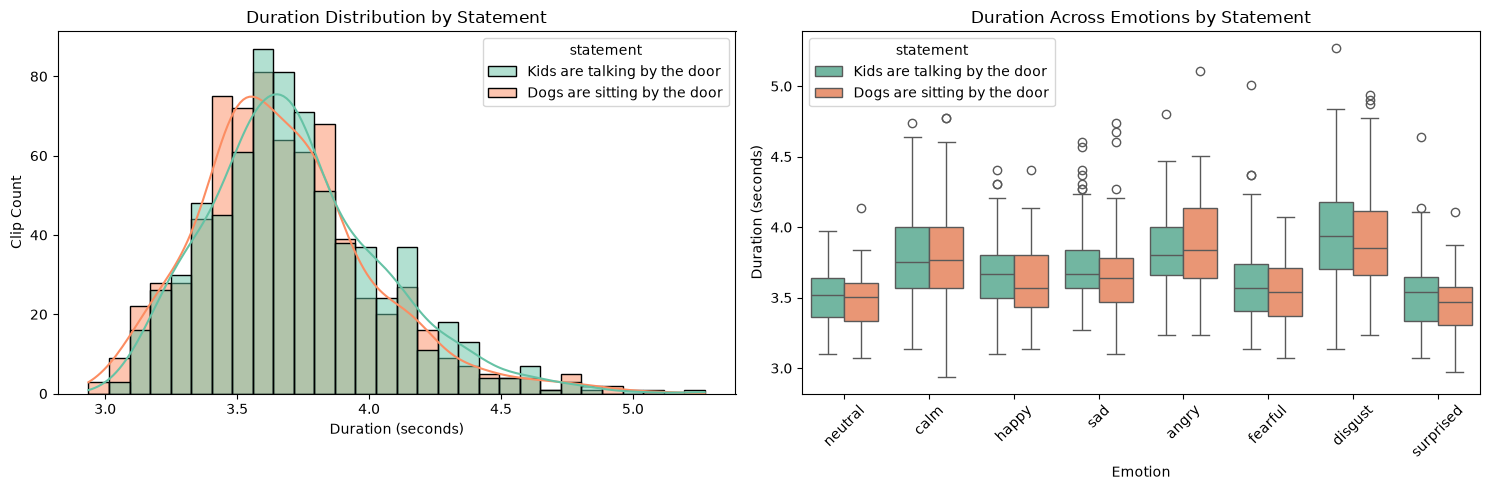

In [9]:
duration_by_statement = (
    df_metadata.groupby("statement")["duration_sec"]
    .agg(
        count="count",
        mean="mean",
        std="std",
        median="median",
        min="min",
        max="max",
    )
    .round(2)
)

print("Duration (seconds) by Statement:")
print(duration_by_statement)

# 2. Granular breakdown: Statement x Emotion interaction
statement_emotion_summary = (
    df_metadata.groupby(["statement", "emotion"])["duration_sec"]
    .mean()
    .unstack()
    .round(2)
)

print("\nMean Duration (seconds) by Statement and Emotion:")
print(statement_emotion_summary)

# 3. Comparative Visualizations
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# KDE / Distribution Plot by Statement
sns.histplot(
    data=df_metadata,
    x="duration_sec",
    hue="statement",
    kde=True,
    bins=30,
    palette="Set2",
    ax=axes[0],
)
axes[0].set_title("Duration Distribution by Statement")
axes[0].set_xlabel("Duration (seconds)")
axes[0].set_ylabel("Clip Count")

# Boxplot: Emotion vs Duration split by Statement
sns.boxplot(
    data=df_metadata,
    x="emotion",
    y="duration_sec",
    hue="statement",
    palette="Set2",
    ax=axes[1],
)
axes[1].set_title("Duration Across Emotions by Statement")
axes[1].set_xlabel("Emotion")
axes[1].set_ylabel("Duration (seconds)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [10]:
duration_by_statement = (
    df_metadata.groupby("statement")["duration_sec"]
    .agg(
        count="count",
        mean="mean",
        std="std",
        median="median",
        min="min",
        max="max",
    )
    .round(2)
)

print("Duration (seconds) by Statement:")
print(duration_by_statement)

Duration (seconds) by Statement:
                              count  mean   std  median   min   max
statement                                                          
Dogs are sitting by the door    720  3.68  0.34    3.64  2.94  5.11
Kids are talking by the door    720  3.72  0.34    3.69  3.07  5.27


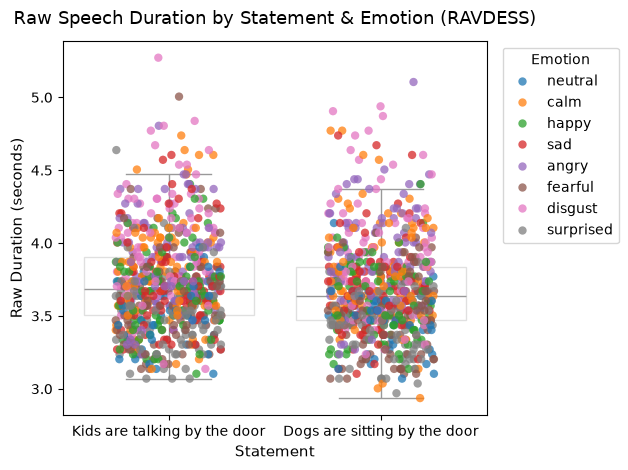

In [11]:
sns.stripplot(
    data=df_metadata,
    x="statement",
    y="duration_sec",
    hue="emotion",
    jitter=0.25,
    alpha=0.75,
    size=6,
    palette="tab10",
)

# Overlay subtle boxplots to show median and IQR per statement
sns.boxplot(
    data=df_metadata,
    x="statement",
    y="duration_sec",
    color="white",
    boxprops=dict(alpha=0.3),
    showcaps=True,
    showfliers=False,
)

plt.title(
    "Raw Speech Duration by Statement & Emotion (RAVDESS)",
    fontsize=13,
    pad=12,
)
plt.xlabel("Statement", fontsize=11)
plt.ylabel("Raw Duration (seconds)", fontsize=11)
plt.legend(
    title="Emotion",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=True,
)
plt.tight_layout()
plt.show()